<a href="https://colab.research.google.com/github/sergiomorapardo/StochasticAITechniquesClass/blob/main/Notebooks/L14_HackathonFraming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook: Hackatón — Encuadre del problema analítico (pronóstico de recaudo a 30 días)

Este notebook prepara la hackatón de la Semana 5. **No resuelve el reto**: explica cómo plantearlo y qué errores de método evitar, con **datos sintéticos** generados aquí mismo. Los nombres de columnas, tipos de movimiento y variables de este notebook son **ilustrativos**: no coinciden con los de las bases reales. Mapearlos con el diccionario de datos es parte del trabajo.

**El reto en una frase:** una empresa de factoring quiere saber cuánto efectivo recibirá en los próximos 30 días por cada factura que tiene abierta.

En este notebook veremos:

1.  **El problema:** de la pregunta de negocio a la pregunta analítica.
2.  **El target:** qué cuenta como recaudo y qué no.
3.  **El corte:** qué documentos entran, qué información se puede usar y qué se predice.
4.  **La vista minable:** de un corte a muchos cortes.
5.  **Fuga de información:** la variable que parece perfecta y no sirve.
6.  **Validación por fecha:** por qué un K-fold aleatorio engaña en este problema.
7.  **Modelos y métricas:** cómo comparar contra un piso, con lo visto en el curso.
8.  **Checklist** de entregables y preparación.

## Preparación

Solo usamos librerías que ya conocen del curso.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. El problema: de la pregunta de negocio a la pregunta analítica

Un **factor** compra facturas a sus **clientes** (empresas proveedoras) y les anticipa parte del valor; el resto lo retiene como reserva. Después cobra la factura a quien la debe, el **pagador**. El factor conoce el valor nominal y la fecha de vencimiento, pero **no sabe cuándo ni cuánto efectivo va a llegar**: los pagadores pagan antes, a tiempo o tarde; pagan parcial; aplican notas crédito; y a veces un pago se reversa.

| Pieza | Definición |
|---|---|
| **Pregunta de negocio** | ¿Cuánta caja entrará en los próximos 30 días por la cartera que ya compramos? |
| **Pregunta analítica** | Regresión supervisada: para cada factura abierta en una fecha de corte, estimar el efectivo neto que recibirá en los días 1 a 30 siguientes. |
| **Unidad de análisis** | Factura × fecha de corte. Una factura aparece en varios cortes mientras siga abierta. |
| **Target** | Efectivo neto (pagos menos sus reversos) aplicado a la factura en la ventana. Cero si no llega nada. |
| **Variables** | Las que diseñe el equipo, siempre con información conocida en la fecha de corte. |
| **Validación** | Cronológica, por fecha de corte. Nunca aleatoria por filas. |
| **Métricas** | Error absoluto medio (MAE) por factura y error absoluto del total de la cartera, en dinero, frente a un pronóstico base. |
| **Producto** | Pronóstico por factura, con totales por cartera, pagador y cliente. |

> **Pregunta para el equipo:** ¿por qué no basta con sumar las facturas que vencen en los próximos 30 días?

## 2. El target: qué cuenta como recaudo

Una factura puede tener muchos movimientos y no todos son dinero que entra. En este ejemplo usamos tipos con nombres descriptivos; en las bases reales cada tipo tiene un **código** y su significado está en el diccionario de datos.

| Tipo (ilustrativo) | Qué es | ¿Es efectivo del pagador? |
|---|---|---|
| `pago` | Pago aplicado a la factura | **Sí** |
| `reverso_pago` | Anulación de un pago anterior; ya viene con signo negativo | **Sí**, con su signo |
| `nota_credito` | Reduce lo que se debe | No |
| `devolucion_credito` | Revierte una nota crédito | No |
| `cierre_reserva` | Cierra la factura usando la reserva retenida | No |
| `no_financiada` | Pago de una factura que el factor no compró | No: no es cartera financiada |

**Ejemplo** (el mismo del enunciado): una factura de 10.000 con estos movimientos después del corte.

In [2]:
mov_ejemplo = pd.DataFrame({
    "fecha":     pd.to_datetime(["2026-09-05", "2026-09-08", "2026-09-15", "2026-09-20"]),
    "tipo":      ["pago", "reverso_pago", "pago", "nota_credito"],
    "caja":      [7_000, -2_000, 3_000, 0],      # dinero que entra (o sale, si es reverso)
    "descuenta": [7_000, -2_000, 3_000, 2_000],  # cuánto reduce lo que se debe
})
display(mov_ejemplo)

EFECTIVO = ["pago", "reverso_pago"]
correcto = mov_ejemplo.loc[mov_ejemplo["tipo"].isin(EFECTIVO), "caja"].sum()
error_1 = mov_ejemplo["descuenta"].sum()                                    # suma todo lo que reduce la deuda
error_2 = mov_ejemplo.loc[mov_ejemplo["tipo"] == "pago", "caja"].sum()      # ignora los reversos

print(f"Recaudo neto correcto (pagos + reversos):  {correcto:>8,.0f}")
print(f"Error 1, sumar todo lo que reduce deuda:   {error_1:>8,.0f}  <- cuenta la nota crédito como si fuera caja")
print(f"Error 2, sumar solo los pagos:             {error_2:>8,.0f}  <- ignora el reverso")

,fecha,tipo,caja,descuenta
0,2026-09-05,pago,7000,7000
1,2026-09-08,reverso_pago,-2000,-2000
2,2026-09-15,pago,3000,3000
3,2026-09-20,nota_credito,0,2000


Recaudo neto correcto (pagos + reversos):     8,000
Error 1, sumar todo lo que reduce deuda:     10,000  <- cuenta la nota crédito como si fuera caja
Error 2, sumar solo los pagos:               10,000  <- ignora el reverso


La factura queda cerrada (10.000 = 8.000 de efectivo + 2.000 de crédito), pero **solo entraron 8.000 a caja**. Cerrar una factura no significa cobrar su valor nominal.

> Un reverso ya viene negativo. Si lo restan otra vez, lo cuentan dos veces.

## 3. El corte: qué entra, qué se puede usar y qué se predice

Un **corte** `T` es una fecha en la que "tomamos una foto" de la cartera. En ese momento hay tres reglas:

1.  **Población:** documentos ya comprados en `T` y con valor pendiente en `T`.
2.  **Variables:** solo se calculan con lo que pasó **hasta** `T`.
3.  **Target:** el efectivo que llega **entre `T+1` y `T+30`**.

Veámoslo con seis documentos inventados y un corte el 31-ago-2026.

In [3]:
T = pd.Timestamp("2026-08-31")
H = 30

docs = pd.DataFrame({
    "documento":     ["D1", "D2", "D3", "D4", "D5", "D6"],
    "fecha_compra":  pd.to_datetime(["2026-07-10", "2026-08-05", "2026-08-12", "2026-07-25", "2026-08-20", "2026-09-10"]),
    "fecha_vence":   pd.to_datetime(["2026-08-20", "2026-09-05", "2026-09-25", "2026-08-25", "2026-09-20", "2026-10-10"]),
    "valor_nominal": [5_000, 4_000, 6_000, 8_000, 3_000, 2_000],
})
movs = pd.DataFrame({
    "documento": ["D1", "D2", "D3", "D4", "D4", "D5", "D6"],
    "fecha":     pd.to_datetime(["2026-08-18", "2026-09-03", "2026-10-10", "2026-08-28", "2026-09-15", "2026-09-22", "2026-10-08"]),
    "tipo":      ["pago", "pago", "pago", "pago", "pago", "cierre_reserva", "pago"],
    "caja":      [5_000, 4_000, 6_000, 5_000, 3_000, 0, 2_000],
    "descuenta": [5_000, 4_000, 6_000, 5_000, 3_000, 3_000, 2_000],
})
display(docs, movs)

,documento,fecha_compra,fecha_vence,valor_nominal
0,D1,2026-07-10,2026-08-20,5000
1,D2,2026-08-05,2026-09-05,4000
2,D3,2026-08-12,2026-09-25,6000
3,D4,2026-07-25,2026-08-25,8000
4,D5,2026-08-20,2026-09-20,3000
5,D6,2026-09-10,2026-10-10,2000


,documento,fecha,tipo,caja,descuenta
0,D1,2026-08-18,pago,5000,5000
1,D2,2026-09-03,pago,4000,4000
2,D3,2026-10-10,pago,6000,6000
3,D4,2026-08-28,pago,5000,5000
4,D4,2026-09-15,pago,3000,3000
5,D5,2026-09-22,cierre_reserva,0,3000
6,D6,2026-10-08,pago,2000,2000


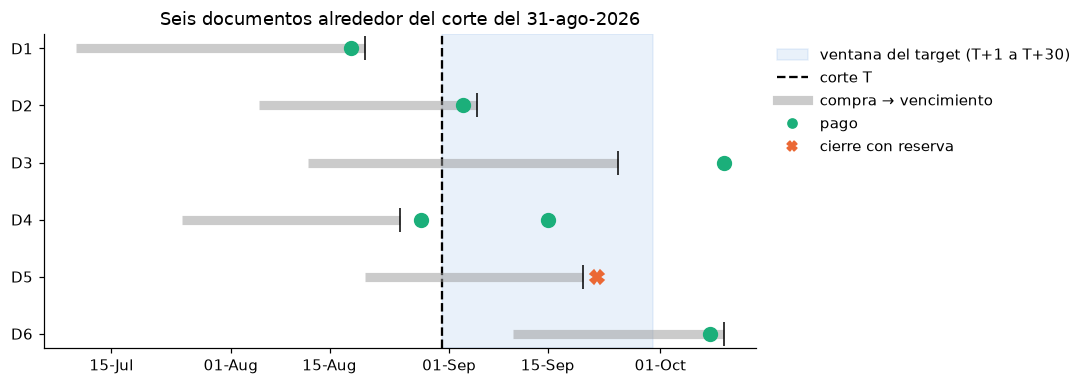

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(T, T + pd.Timedelta(days=H), color="#2a78d6", alpha=0.10, label="ventana del target (T+1 a T+30)")
ax.axvline(T, color="black", lw=1.5, ls="--", label="corte T")
estilo = {"pago": dict(marker="o", color="#1baf7a"), "cierre_reserva": dict(marker="X", color="#eb6834")}
for i, d in enumerate(docs.itertuples()):
    ax.plot([d.fecha_compra, d.fecha_vence], [i, i], color="#999999", lw=6, solid_capstyle="butt", alpha=0.5)
    ax.plot(d.fecha_vence, i, marker="|", ms=16, color="black")
    for m in movs[movs["documento"] == d.documento].itertuples():
        ax.plot(m.fecha, i, ms=9, ls="none", **estilo[m.tipo])
ax.plot([], [], color="#999999", lw=6, alpha=0.5, label="compra → vencimiento")
ax.plot([], [], ls="none", label="pago", **estilo["pago"])
ax.plot([], [], ls="none", label="cierre con reserva", **estilo["cierre_reserva"])
ax.set_yticks(range(len(docs)), docs["documento"]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title("Seis documentos alrededor del corte del 31-ago-2026")
plt.tight_layout(); plt.show()

Antes de ver la respuesta, **decidan para cada documento**: ¿entra al corte? ¿cuál es su target?

In [5]:
descontado_hasta_T = movs[movs["fecha"] <= T].groupby("documento")["descuenta"].sum()
en_ventana = movs[(movs["fecha"] > T) & (movs["fecha"] <= T + pd.Timedelta(days=H)) & movs["tipo"].isin(EFECTIVO)]

foto = docs.set_index("documento")
foto["comprado_en_T"] = foto["fecha_compra"] <= T
foto["pendiente_en_T"] = foto["valor_nominal"] - descontado_hasta_T.reindex(foto.index, fill_value=0)
foto["entra_al_corte"] = foto["comprado_en_T"] & (foto["pendiente_en_T"] > 0)
foto["target_30d"] = en_ventana.groupby("documento")["caja"].sum().reindex(foto.index, fill_value=0)
foto.loc[~foto["entra_al_corte"], "target_30d"] = np.nan
display(foto[["valor_nominal", "comprado_en_T", "pendiente_en_T", "entra_al_corte", "target_30d"]])

,valor_nominal,comprado_en_T,pendiente_en_T,entra_al_corte,target_30d
documento,,,,,
D1,5000,True,0,False,NaN
D2,4000,True,4000,True,"4,000.00"
D3,6000,True,6000,True,0.00
D4,8000,True,3000,True,"3,000.00"
D5,3000,True,3000,True,0.00
D6,2000,False,2000,False,NaN


| Documento | ¿Qué pasó? | Lección |
|---|---|---|
| D1 | Se pagó antes del corte | Ya no está abierto: **no entra** |
| D2 | Paga completo dentro de la ventana | Target = 4.000 |
| D3 | Paga después de la ventana | **Entra con target 0.** No se borra: el cero también se aprende |
| D4 | Pagó 5.000 antes del corte y 3.000 dentro de la ventana | Lo pendiente en `T` es 3.000, no 8.000. Target = 3.000 |
| D5 | Se cierra con reserva | Se cierra, pero no entra caja: target 0 |
| D6 | Se compró después del corte | **No entra**: no existía en `T` |

> D4 ya estaba vencido en el corte y aun así paga. El vencimiento **orienta**, pero no decide.

## 4. La vista minable: de un corte a muchos cortes

Un solo corte da pocas filas para entrenar. La idea es **repetir la foto en cada cierre de mes** de la historia (el enunciado propone del 31-ene-2023 al 30-jun-2026 para entrenar) y apilar los resultados:

| documento | corte | variable 1 | variable 2 | … | **target 30 d** |
|---|---|---|---|---|---|
| D3 | 2026-08-31 | … | … | … | 0 |
| D3 | 2026-09-30 | … | … | … | 6.000 |
| D4 | 2026-08-31 | … | … | … | 3.000 |
| … | … | … | … | … | … |

Fíjense en que **D3 aparece dos veces**: estaba abierto en dos cortes. Eso tiene consecuencias en las secciones 5 y 6.

Construir esta tabla con los datos reales, y decidir qué variables tiene, es el corazón del reto. Algunas preguntas que les toca responder:

- ¿Cómo se unen las bases? ¿La llave que eligieron identifica una sola factura? Compruébenlo con los datos.
- ¿Cómo se calcula lo pendiente de cada factura en cada corte?
- ¿Qué información conocida en el corte podría anticipar el pago? Justifiquen cada variable.
- ¿La fecha de los movimientos es la fecha en que se conoció el dato? Si no, declárenlo como limitación.

Para las secciones siguientes usamos una vista minable **sintética** con variables anónimas `x1` a `x4` y un `grupo`. No significan nada del negocio real: sirven para ilustrar problemas de método.

In [6]:
def synthetic_panel(seed=7, n_docs=2500, n_grupos=10):
    """Vista minable sintética: documentos que aparecen en varios cortes hasta que se cobran o se cierran sin caja.
    Las variables x1..x4 son anónimas y el mecanismo es inventado; no usa ni imita datos reales."""
    rng = np.random.default_rng(seed)
    cortes = pd.date_range("2023-01-31", "2026-08-31", freq="ME")
    grupos = pd.DataFrame({"grupo": [f"G{i:02d}" for i in range(n_grupos)],
                           "efecto": rng.normal(0, 0.8, n_grupos),
                           "deriva": rng.choice([0, 0, 0, 0.8, -0.8], n_grupos)})   # cambio por año
    filas = []
    for doc in range(1, n_docs + 1):
        g = grupos.iloc[rng.integers(n_grupos)]
        valor = round(float(np.exp(rng.normal(9, 0.5))), 2)
        x1_ini, x3, x4 = rng.uniform(0, 3), rng.normal(), rng.normal()
        u = rng.normal(0, 3.0)              # rasgo propio del documento que no se observa
        inicio, k_max = rng.integers(len(cortes)), rng.integers(1, 7)
        for k in range(k_max):
            if inicio + k >= len(cortes):
                break
            corte = cortes[inicio + k]
            x1 = x1_ini - k + rng.normal(0, 0.2)
            anios = (corte - cortes[0]).days / 365
            p = 1 / (1 + np.exp(-(0.3 - 0.9 * x1 + 0.6 * x3 + u + g.efecto + (g.deriva - 0.4) * anios)))
            cobra = rng.random() < p
            filas.append({"documento": doc, "grupo": g.grupo, "corte": corte, "x1": x1, "x3": x3, "x4": x4,
                          "pendiente": valor, "target": valor if cobra else 0.0})
            if cobra:
                break
    panel = pd.DataFrame(filas)
    # x2: tasa de cobro del grupo en los últimos 12 meses con target ya conocido en el corte
    x2 = {}
    for T in cortes:
        h = panel[(panel["corte"] + pd.Timedelta(days=30) <= T) & (panel["corte"] > T - pd.Timedelta(days=365))]
        x2[T] = (h["target"] > 0).groupby(h["grupo"]).mean()
    panel["x2"] = [x2[T].get(g, np.nan) for T, g in zip(panel["corte"], panel["grupo"])]
    panel["x2"] = panel["x2"].fillna((panel["target"] > 0).mean())
    return panel[["documento", "grupo", "corte", "x1", "x2", "x3", "x4", "pendiente", "target"]]

panel = synthetic_panel()
print(f"Vista minable sintética: {len(panel):,} filas | {panel['corte'].nunique()} cortes | {panel['documento'].nunique():,} documentos")
print(f"Filas por documento: media {panel.groupby('documento').size().mean():.1f} (un documento aparece en varios cortes)")
print(f"Filas con target = 0: {(panel['target'] == 0).mean():.0%}")
display(panel.sort_values(["documento", "corte"]).head(6))

Vista minable sintética: 5,766 filas | 44 cortes | 2,500 documentos
Filas por documento: media 2.3 (un documento aparece en varios cortes)
Filas con target = 0: 75%


,documento,grupo,corte,x1,x2,x3,x4,pendiente,target
0,1,G05,2025-01-31,2.12,0.26,-1.90,-1.29,"4,137.69",0.00
1,1,G05,2025-02-28,1.41,0.26,-1.90,-1.29,"4,137.69",0.00
2,1,G05,2025-03-31,-0.13,0.23,-1.90,-1.29,"4,137.69",0.00
3,1,G05,2025-04-30,-0.63,0.22,-1.90,-1.29,"4,137.69",0.00
4,1,G05,2025-05-31,-1.93,0.21,-1.90,-1.29,"4,137.69",0.00
5,1,G05,2025-06-30,-2.59,0.18,-1.90,-1.29,"4,137.69",0.00


> La función de arriba es un **simulador** con variables inventadas, no la solución. Con los datos reales hay pagos parciales, reversos, créditos, cierres con reserva, pagos de facturas no financiadas y llaves que comprobar. Nada de eso está aquí.

## 5. Fuga de información: la variable que parece perfecta

La **fuga de información** (*data leakage*) ocurre cuando una variable usa datos que no se conocían en la fecha de corte. El modelo se ve excelente en la evaluación y falla en producción.

Primer ejemplo: `x2` es la tasa de cobro del grupo en los 12 meses previos al corte. Así calculada es legítima. Un promedio **con toda la historia**, en cambio, mezcla lo que el grupo hará en el futuro.

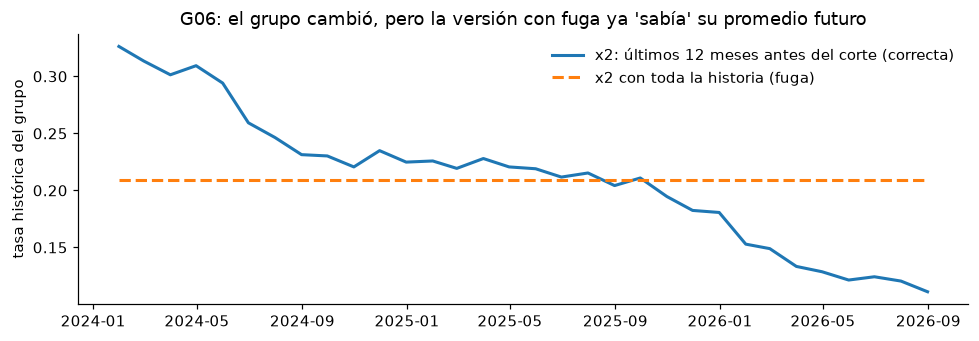

In [7]:
x2_completa = (panel["target"] > 0).groupby(panel["grupo"]).mean().rename("x2_completa")
panel = panel.merge(x2_completa, on="grupo")

desde = pd.Timestamp("2024-01-31")    # antes no hay 12 meses de historia
serie_por_grupo = {g: d[d["corte"] >= desde].groupby("corte")["x2"].first() for g, d in panel.groupby("grupo")}
g_ej = max(serie_por_grupo, key=lambda g: abs(serie_por_grupo[g].iloc[-1] - serie_por_grupo[g].iloc[0]))
serie = panel[(panel["grupo"] == g_ej) & (panel["corte"] >= desde)].groupby("corte")[["x2", "x2_completa"]].first()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(serie.index, serie["x2"], lw=2, label="x2: últimos 12 meses antes del corte (correcta)")
ax.plot(serie.index, serie["x2_completa"], lw=2, ls="--", label="x2 con toda la historia (fuga)")
ax.set_ylabel("tasa histórica del grupo"); ax.legend(frameon=False)
ax.set_title(f"{g_ej}: el grupo cambió, pero la versión con fuga ya 'sabía' su promedio futuro")
plt.tight_layout(); plt.show()

Segundo ejemplo, más dañino: una variable calculada **con los movimientos de la propia ventana del target**. Por ejemplo, "qué fracción de los documentos del grupo se cobró en este corte". Suena a un patrón histórico, pero usa el futuro.

In [8]:
def mae(y, yhat):
    return np.mean(np.abs(np.asarray(y) - np.asarray(yhat)))

# Variable con fuga: usa lo que pasa en la ventana T+1..T+30, es decir, el propio target
panel["x_fuga"] = panel.groupby(["grupo", "corte"])["target"].transform(lambda s: (s > 0).mean())

train = panel[panel["corte"] <= "2025-12-31"]
test = panel[panel["corte"] > "2025-12-31"]
resultado = {}
for nombre, cols in [("sin fuga (x1..x4)", ["x1", "x2", "x3", "x4"]), ("con fuga (+ x_fuga)", ["x1", "x2", "x3", "x4", "x_fuga"])]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[cols], train["target"] > 0)
    resultado[nombre] = mae(test["target"], clf.predict_proba(test[cols])[:, 1] * test["pendiente"])
display(pd.Series(resultado, name="MAE por documento en 2026").to_frame())

,MAE por documento en 2026
sin fuga (x1..x4),"3,098.26"
con fuga (+ x_fuga),"2,787.87"


Con la variable con fuga el error baja, incluso evaluando por fecha. **Esa mejora es falsa**: el día que pronostiquen la cartera actual, los movimientos del próximo mes todavía no existen y la variable no se puede calcular.

**Regla práctica:** para cada variable pregúntense *"¿el analista podía calcular este número el día del corte?"*. Si una variable mejora el modelo "demasiado", sospechen de ella primero.

## 6. Validación por fecha, no aleatoria

En el curso usamos `train_test_split` y K-fold con partición aleatoria ([L6](L6_CrossValidation.ipynb)). Aquí eso **engaña**, por dos razones:

1.  **El mismo documento aparece en varios cortes** con variables casi iguales. Si una fila queda en train y su "gemela" en test, el modelo solo tiene que memorizarla.
2.  **El objetivo es predecir el futuro.** La evaluación tiene que imitar ese uso: entrenar con el pasado y medir con cortes posteriores.

Comparemos un árbol de decisión ([L9](L9_NaiveBayes_CART.ipynb)) evaluado de las dos formas. Como los periodos tienen montos distintos, comparamos el **error relativo** (WAPE = suma de errores absolutos / suma del recaudo real).

In [9]:
X_cols = ["x1", "x2", "x3", "x4", "pendiente"]
arbol = lambda: DecisionTreeRegressor(min_samples_leaf=5, random_state=0)
frac = panel["target"] / panel["pendiente"]

def wape(y, yhat):
    return np.sum(np.abs(np.asarray(y) - np.asarray(yhat))) / np.sum(y)

# (a) Lo que promete un K-fold aleatorio por filas
errores = []
for tr_i, te_i in KFold(5, shuffle=True, random_state=0).split(panel):
    m = arbol().fit(panel.iloc[tr_i][X_cols], frac.iloc[tr_i])
    errores.append(wape(panel.iloc[te_i]["target"], m.predict(panel.iloc[te_i][X_cols]) * panel.iloc[te_i]["pendiente"]))

# (b) Lo que pasa de verdad: entrenar con el pasado (hasta dic-2025) y pronosticar 2026
m = arbol().fit(train[X_cols], train["target"] / train["pendiente"])
real = wape(test["target"], m.predict(test[X_cols]) * test["pendiente"])

display(pd.Series({"Lo que promete el K-fold aleatorio": np.mean(errores), "Lo que se obtiene en el futuro (2026)": real},
                  name="WAPE").to_frame().style.format("{:.1%}"))

,WAPE
Lo que promete el K-fold aleatorio,143.8%
Lo que se obtiene en el futuro (2026),167.5%


El K-fold aleatorio promete un error menor del que el modelo tiene de verdad cuando pronostica cortes futuros: entrenó con filas "gemelas" de los mismos documentos y con información de periodos posteriores. (Un WAPE por documento mayor a 100 % es normal aquí: la mayoría de filas tiene target 0 y cada documento se cobra todo o nada. Lo que importa es la diferencia entre las dos cifras.) Por eso el enunciado fija la evaluación **por fecha de corte**:

| Etapa | Cortes | Uso |
|---|---|---|
| Entrenamiento | Cierres de mes, 31-ene-2023 a 30-jun-2026 | Ajustar modelos |
| Validación | 31-jul-2026 | Elegir modelo e hiperparámetros |
| Prueba final | 31-ago-2026 | Reportar una sola vez. **No se usa para elegir** |
| Pronóstico | Fecha de la cartera actual | Sin respuesta conocida todavía |

Si quieren ajustar hiperparámetros con validación cruzada, háganlo **por bloques de fechas**, nunca mezclando filas al azar.

## 7. Modelos y métricas

Antes de cualquier modelo sofisticado necesitan un **piso**: si el modelo no supera una regla simple, no aporta. El enunciado pide comparar contra un **pronóstico base por vencimientos**: piensen ustedes cómo construirlo con las fechas de los datos reales. Aquí, como el simulador no tiene fechas de vencimiento, usamos como piso la tasa global histórica de cobro.

Con lo visto en el curso tienen un menú suficiente:

| Modelo | Dónde lo vimos |
|---|---|
| Regresión lineal regularizada (Ridge, Lasso) | [L4b](L4b_Regularization.ipynb) |
| Regresión logística ("¿llega efectivo?") × valor pendiente | [L5](L5_LogisticRegression.ipynb) |
| KNN de regresión | [L8](L8_KNN.ipynb) |
| Árbol de regresión (CART) | [L9](L9_NaiveBayes_CART.ipynb) |

Y dos métricas mínimas, **en dinero**:

- **MAE por factura:** promedio de |pronóstico − real|. ¿Sirve para decisiones individuales?
- **Error absoluto del total:** |suma de pronósticos − suma real| en el corte. ¿Sirve para la caja de la empresa?

In [10]:
TRAIN_FIN, VAL, TEST = pd.Timestamp("2026-06-30"), pd.Timestamp("2026-07-31"), pd.Timestamp("2026-08-31")
tr, va, te = panel[panel["corte"] <= TRAIN_FIN], panel[panel["corte"] == VAL], panel[panel["corte"] == TEST]
X_cols = ["x1", "x2", "x3", "x4"]

def piso_tasa_global(tr, df):
    return np.full(len(df), tr["target"].sum() / tr["pendiente"].sum()) * df["pendiente"].to_numpy()

def ridge(tr, df):
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(tr[X_cols], tr["target"] / tr["pendiente"])
    return np.clip(m.predict(df[X_cols]), 0, 1) * df["pendiente"]

def logistica(tr, df):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[X_cols], tr["target"] > 0)
    return m.predict_proba(df[X_cols])[:, 1] * df["pendiente"]

def arbol_cart(tr, df):
    m = DecisionTreeRegressor(max_depth=4, min_samples_leaf=30, random_state=0).fit(tr[X_cols], tr["target"] / tr["pendiente"])
    return m.predict(df[X_cols]) * df["pendiente"]

MODELOS = {"Piso: tasa global": piso_tasa_global, "Ridge": ridge, "Logística × pendiente": logistica, "Árbol CART": arbol_cart}

filas = []
for nombre, f in MODELOS.items():
    yv = f(tr, va)
    filas.append({"modelo": nombre, "MAE por documento (val)": mae(va["target"], yv),
                  "Error abs. del total (val)": abs(np.sum(yv) - va["target"].sum()), "Total pronosticado (val)": np.sum(yv)})
tabla = pd.DataFrame(filas).set_index("modelo").sort_values("MAE por documento (val)")
print(f"Validación {VAL.date()}: {len(va)} documentos abiertos | recaudo real {va['target'].sum():,.0f}")
display(tabla.style.format("{:,.0f}"))

Validación 2026-07-31: 134 documentos abiertos | recaudo real 276,019


,MAE por documento (val),Error abs. del total (val),Total pronosticado (val)
modelo,,,
Árbol CART,"3,141","10,442","286,461"
Ridge,"3,192","20,093","296,112"
Logística × pendiente,"3,208","23,169","299,188"
Piso: tasa global,"3,437","47,373","323,392"


In [11]:
elegido = tabla.index[0]
y_test = MODELOS[elegido](panel[panel["corte"] <= VAL], te)    # se reentrena con todo lo conocido al cierre de validación
print(f"Modelo elegido en validación: {elegido}")
print(f"Prueba {TEST.date()}: MAE por documento {mae(te['target'], y_test):,.0f} | "
      f"total real {te['target'].sum():,.0f} | pronosticado {np.sum(y_test):,.0f} | "
      f"error abs. del total {abs(np.sum(y_test) - te['target'].sum()):,.0f}")

Modelo elegido en validación: Árbol CART
Prueba 2026-08-31: MAE por documento 2,990 | total real 236,936 | pronosticado 273,503 | error abs. del total 36,567


**Para leer los resultados:**

- Un modelo puede ganar en MAE por factura y perder en el total (o al revés). Reporten **las dos métricas** y expliquen cuál importa más para Operaciones.
- El modelo se elige con **validación**; la prueba se mira **una vez** al final. Si después de mirar la prueba cambian de modelo, la prueba deja de ser prueba.
- Revisen dónde se equivoca el modelo, no solo el promedio: en carteras reales unos pocos documentos grandes pueden mover el total.

> En este simulador cada documento se cobra completo o no se cobra, así que "logística × pendiente" es directamente el valor esperado. Con los datos reales hay pagos parciales: piensen si les conviene modelar también el monto.

## 8. Checklist de entregables y preparación

**Al cierre de la hackatón** (según el enunciado):

- [ ] **Notebook reproducible**: integración, limpieza, vista minable, modelos y evaluación.
- [ ] **Vista minable documentada**: unidad de análisis, llaves, reglas del target y variables (con su justificación).
- [ ] **Modelo reproducible**: recibe una cartera en una fecha de corte y devuelve un monto por factura. Si solo funciona para una fecha, no es reproducible.
- [ ] **Tabla de pronósticos sobre la cartera actual**: factura, cliente, pagador, saldo al corte, monto esperado a 30 días y totales por cliente, pagador y cartera.
- [ ] **Comparación con el pronóstico base** y explicación de las métricas.
- [ ] **Pitch** para el equipo de Operaciones: desarrollo del modelo, resultados, limitaciones y recomendaciones.
- [ ] *(Opcional)* Ventana aproximada de recaudo: días 1–10, 11–20, 21–30 o sin recaudo.

**Antes de la hackatón** (obligatorio):

- [ ] Revisar las cuatro bases, el enunciado y el diccionario, y **traer preguntas para los representantes de la empresa**.
- [ ] **Estado del arte**: buscar artículos sobre predicción de pagos de facturas, *cash-flow forecasting* o *accounts receivable* en las bases de datos de la Universidad.

**Errores que más cuestan puntos:**

1.  Usar información posterior al corte en las variables (sección 5).
2.  Evaluar con particiones aleatorias (sección 6).
3.  Contar como efectivo movimientos que no lo son (sección 2).
4.  Borrar los documentos que no pagaron en la ventana: su target es 0 y el modelo tiene que aprenderlo (sección 3).
5.  No comparar contra un pronóstico base (sección 7).

## Conclusión

El reto no es elegir el algoritmo más sofisticado. Es **plantear bien el problema**: definir el target con las reglas del negocio, construir una vista minable sin fuga de información y evaluar como si estuvieran en la fecha de corte. Con eso, los modelos que ya conocen son un punto de partida sólido.

**Material de apoyo de hackatones anteriores:** [L11: Time Series](L11_TimeSeries.ipynb) (variables con rezagos y split cronológico), [L12: Multi-horizonte](L12_TimeSeries_MultiHorizont.ipynb) y [L13: Isolation Forest](L13_iforest_heristics.ipynb) (empaquetar el pipeline para ejecutarlo sobre un nuevo periodo).